# SiN Photonic-Crystal Nanocavities III — Nanobeam Cavities and the Comparison

Notebook 02 showed that a 2D slab cavity in SiN saturates at Q ≈ 3×10³: at n = 2.0 the light
cone takes too much of k-space. A **nanobeam** confines light differently: along the beam by
a 1D Bragg mirror, and across it by total internal reflection in two directions. Its mode can
be shaped with a gentle taper of the mirror so that almost no momentum components fall into
the light cone, and SiN nanobeams have been designed to Q > 10⁵ and fabricated to
Q ≈ 5.5×10⁴ in the visible (McCutcheon & Lončar 2008; Khan et al. 2011).

This notebook:
1. reproduces the McCutcheon–Lončar SiN nanobeam (Opt. Express 16, 19136 (2008)), which
   validates the 3D model;
2. simulates the own design of notebook 01 (Quan–Lončar taper, 15 and 20 segments) and
   retunes it to 637 nm;
3. checks its fabrication tolerance (±5 nm hole radius and membrane thickness);
4. compares the L3 and the nanobeam: λ, Q, V, Purcell factor, footprint and tolerance.

**Model:** 3D Meep, bulk SiN n = 2.0 and air, non-dispersive and lossless; ridge 300 nm ×
200 nm suspended in air, 0.6 µm (≈ 0.9 λ0) of air and a 0.5 µm (≈ 0.8 λ0) PML around it; same method as notebook 02 (Gaussian Ey pulse, Harminv ring-down,
three mirror planes, V from the field, F = 3/(4π²) Q/V).

**Kernel:** `mp` conda env, run from `sin_cavity/notebooks/`. All 3D runs come from
`scripts/run_nanobeam.py` (12 MPI ranks, 64 px/µm unless stated) and are cached in
`data/nanobeam/`. **Do not use "Run All."**

## 0. Setup

In [1]:
# Imports, style, cached runs.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from pic_toolkit import style
from pic_toolkit.meep_sim import phc_cavity as pc

style.apply_style()
DATA = Path.cwd().parent / "data"
NB = DATA / "nanobeam"


def load(tag, folder=NB):
    # One cached ring-down: geometry, the Harminv mode list and the chosen mode's f, Q, V, F.
    return dict(np.load(folder / f"{tag}.npz"))


def summary(o):
    return f"lambda {1e3 / o['f']:.1f} nm, Q {o['Q']:.3g}, V {o['V']:.2f} (lambda/n)^3, F {o['purcell']:.3g}"


def axis_profile(o):
    # |E|^2 along the beam axis (y = z = 0), normalized, and its x coordinates.
    e2 = o["e2_mid"][:, o["e2_mid"].shape[1] // 2]
    x = np.linspace(-o["box"][0] / 2, o["box"][0] / 2, len(e2))
    return x, e2 / e2.max()

> **STOP -- every run in this section takes 1–2 h on 12 cores; the cells only read the cache.**

## 1. Reproducing McCutcheon & Lončar (2008)

Their design (notebook 01, Section 3): mirror a = 250 nm, r = 70 nm, 17 periods per side, a
four-hole taper to (214, 55) nm, and a cavity gap s between the two innermost holes, taken as
their edge-to-edge distance. They report **Q = 2.3×10⁵ and V = 0.55 (λ/n)³ at s = 95 nm**
(Lumerical 3D FDTD, 5 nm mesh), and show that Q is sharply peaked in s.

First the numerical settings: resolution, air padding above and below the beam, and the
ring-down time Harminv fits.

In [2]:
# Convergence of the reproduction at s = 95 nm.
for tag, what in (("mcc_edge_res64", "64 px/um (reference)"), ("mcc_edge_res80", "80 px/um"),
                  ("mcc_edge_res64_pad1", "air padding 0.6 -> 1.0 um"),
                  ("mcc_edge_res64_ring1000", "ring-down 300 -> 1000 (1/c um)")):
    print(f"{what:>32}: {summary(load(tag))}")

            64 px/um (reference): lambda 649.0 nm, Q 3.66e+04, V 0.54 (lambda/n)^3, F 5.12e+03
                        80 px/um: lambda 649.2 nm, Q 3.62e+04, V 0.54 (lambda/n)^3, F 5.05e+03
       air padding 0.6 -> 1.0 um: lambda 649.0 nm, Q 3.66e+04, V 0.54 (lambda/n)^3, F 5.12e+03
  ring-down 300 -> 1000 (1/c um): lambda 649.0 nm, Q 3.65e+04, V 0.54 (lambda/n)^3, F 5.11e+03


Going from 64 to 80 px/µm changes Q by 1 % and the wavelength by 0.2 nm; more air or a
3.3× longer ring-down changes nothing. 64 px/µm (15.6 nm grid, with Meep's subpixel averaging
of the hole edges) is used throughout.

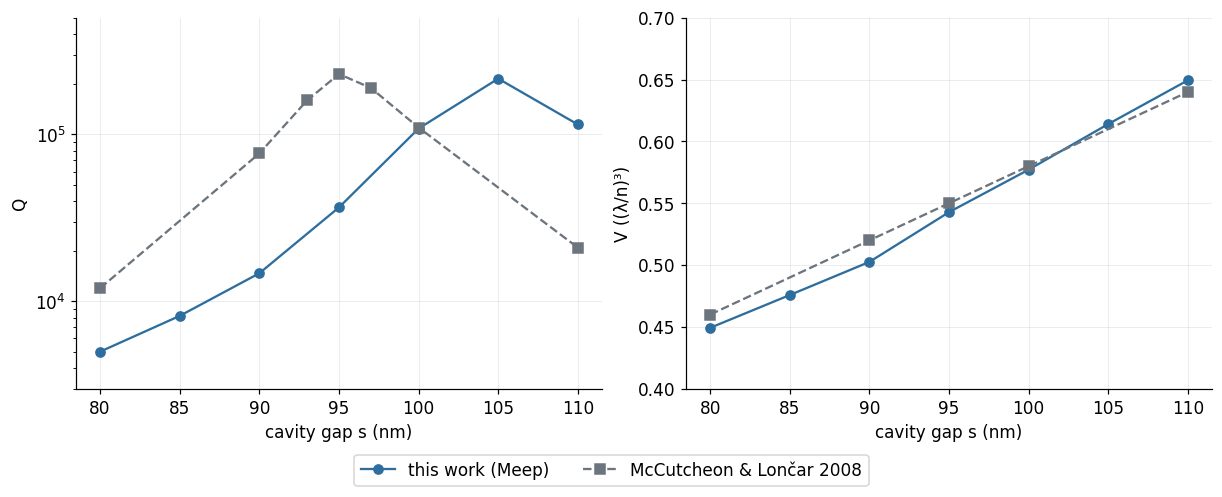

s =  80 nm: lambda 642.4 nm, Q 5e+03, V 0.45 (lambda/n)^3, F 846
s =  85 nm: lambda 644.8 nm, Q 8.19e+03, V 0.48 (lambda/n)^3, F 1.31e+03
s =  90 nm: lambda 646.9 nm, Q 1.48e+04, V 0.50 (lambda/n)^3, F 2.23e+03
s =  95 nm: lambda 649.0 nm, Q 3.66e+04, V 0.54 (lambda/n)^3, F 5.12e+03
s = 100 nm: lambda 651.2 nm, Q 1.08e+05, V 0.58 (lambda/n)^3, F 1.43e+04
s = 105 nm: lambda 653.0 nm, Q 2.16e+05, V 0.61 (lambda/n)^3, F 2.67e+04
s = 110 nm: lambda 654.8 nm, Q 1.15e+05, V 0.65 (lambda/n)^3, F 1.34e+04


In [3]:
# Q and V vs the cavity gap s: this work vs McCutcheon & Loncar (values read from their Fig. 4).
s_ours = [80, 85, 90, 95, 100, 105, 110]
runs = {s: load("mcc_edge_res64" if s == 95 else f"mcc_edge_s{s}") for s in s_ours}
paper_s = [80, 90, 93, 95, 97, 100, 110]
paper_q = [1.2e4, 7.7e4, 1.6e5, 2.3e5, 1.9e5, 1.1e5, 2.1e4]
paper_v = {80: 0.46, 90: 0.52, 95: 0.55, 100: 0.58, 110: 0.64}

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
ax0.semilogy(s_ours, [runs[s]["Q"] for s in s_ours], "o-", color=style.COLOR_STEEL, label="this work (Meep)")
ax0.semilogy(paper_s, paper_q, "s--", color=style.COLOR_REFERENCE, label="McCutcheon & Lončar 2008")
ax0.set_xlabel("cavity gap s (nm)"); ax0.set_ylabel("Q"); ax0.set_ylim(3e3, 5e5)
ax1.plot(s_ours, [runs[s]["V"] for s in s_ours], "o-", color=style.COLOR_STEEL)
ax1.plot(list(paper_v), list(paper_v.values()), "s--", color=style.COLOR_REFERENCE)
ax1.set_xlabel("cavity gap s (nm)"); ax1.set_ylabel("V ((λ/n)³)"); ax1.set_ylim(0.4, 0.7)
fig.legend(*ax0.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2)
fig.savefig(DATA / "fig_nanobeam_reproduction.png", dpi=150, bbox_inches="tight")
plt.show()
for s in s_ours:
    print(f"s = {s:3d} nm: {summary(runs[s])}")

The model reproduces the paper's behaviour: Q is sharply peaked in s, the peak value
(2.2×10⁵ at s = 105 nm here, 2.3×10⁵ at 95 nm in the paper) agrees within 6 %, and V
rises from 0.45 to 0.65 (λ/n)³ across the scan, matching the paper's 0.46–0.64 at the same
s. Two differences remain: the peak sits 10 nm larger in s, and the wavelength is longer,
by 1.9 % at s = 95 nm (649 nm) and 2.5 % at the Q peak (653 nm). Both are what a few nm difference in effective hole size or
beam dimensions does to a design this sensitive (a 5 nm change in s alone moves Q by 2×).
Q, V and the sharp Q-vs-s peak are reproduced; the wavelength is slightly outside 2 %
agreement (2.5 %). Details: `docs/simulation_settings_record.md`.

## 2. Own design: Quan–Lončar taper

The taper of notebook 01 (constant a = 250 nm, centre hole 92 nm, quadratic filling-fraction
taper to 70 nm over N = 15 or 20 holes, then 10 mirror holes, zero cavity length). The N = 15
design came out at 643 nm; scaling every in-plane dimension (hole positions, radii, beam width)
by 0.989 at fixed 200 nm thickness gives **N15s**, at 637 nm.

In [4]:
# Own designs vs the McCutcheon reproduction (s = 105 nm, its Q peak).
own = {"McCutcheon & Lončar (s = 105 nm)": load("mcc_edge_s105"), "own N = 15": load("own_N15"),
       "own N = 20": load("own_N20"), "own N = 15, retuned (N15s)": load("own_N15s")}
for name, o in own.items():
    print(f"{name:>32}: {summary(o)}")
print("\nHarminv modes of own N = 15 (all even about x = 0):")
for f, q, amp, err in np.real(own["own N = 15"]["modes"]):
    print(f"  {1e3 / f:6.1f} nm  Q {q:9.3g}  |amp| {amp:6.2f}")

McCutcheon & Lončar (s = 105 nm): lambda 653.0 nm, Q 2.16e+05, V 0.61 (lambda/n)^3, F 2.67e+04
                      own N = 15: lambda 642.9 nm, Q 5.94e+06, V 1.01 (lambda/n)^3, F 4.46e+05
                      own N = 20: lambda 641.5 nm, Q 1.78e+07, V 0.89 (lambda/n)^3, F 1.53e+06
      own N = 15, retuned (N15s): lambda 636.6 nm, Q 1.39e+06, V 1.65 (lambda/n)^3, F 6.4e+04

Harminv modes of own N = 15 (all even about x = 0):
   642.9 nm  Q  5.94e+06  |amp|  16.39
   663.1 nm  Q  3.31e+04  |amp|   2.09
   678.4 nm  Q       585  |amp|   0.13
   690.3 nm  Q       178  |amp|   0.02


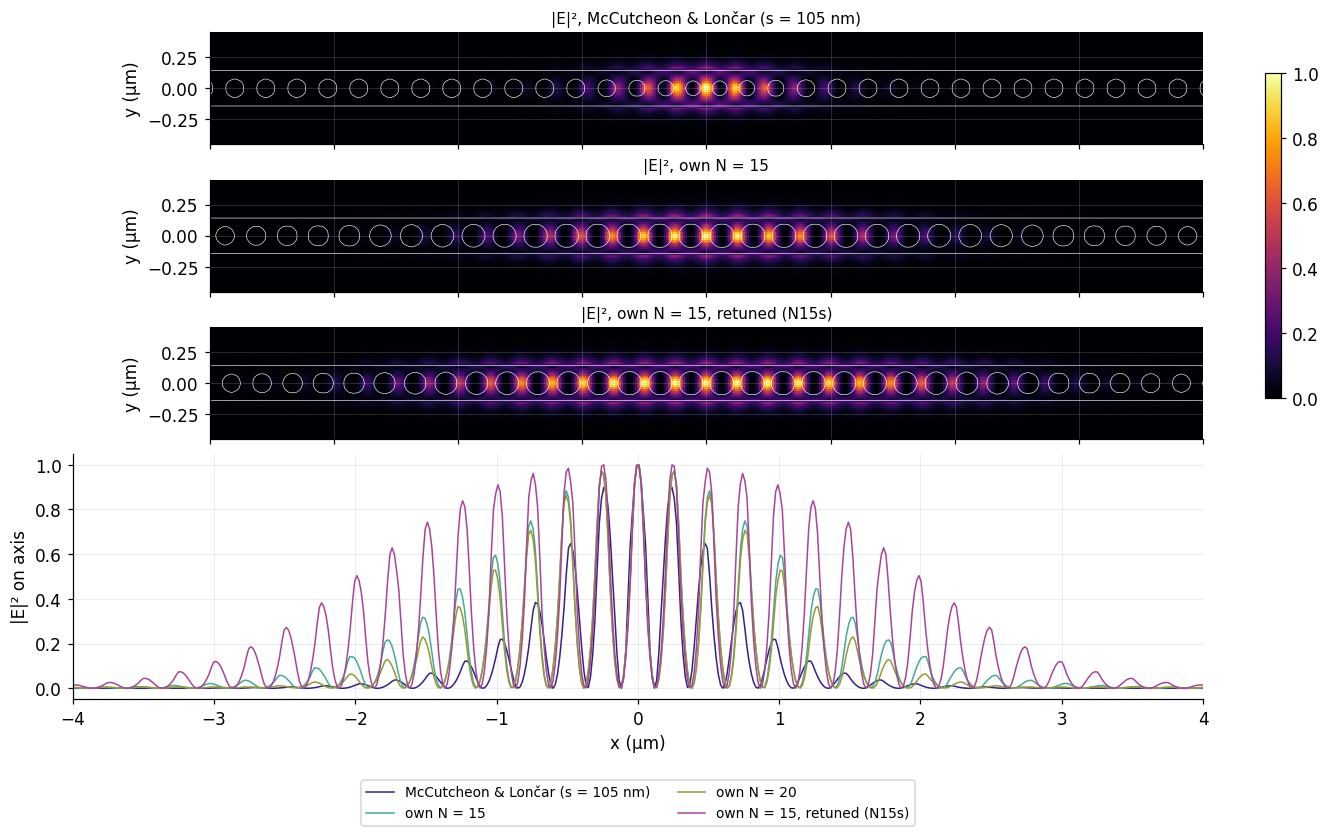

In [5]:
# |E|^2 in the mid-plane of the beam (top three) and on the beam axis (bottom).
show = ["McCutcheon & Lončar (s = 105 nm)", "own N = 15", "own N = 15, retuned (N15s)"]
fig, axes = plt.subplots(4, 1, figsize=(12, 7.5), layout="constrained",
                         gridspec_kw=dict(height_ratios=[1, 1, 1, 2.2]))
for ax, name in zip(axes, show):
    o = own[name]
    bx, by = o["box"][:2]
    x = np.linspace(-bx / 2, bx / 2, o["e2_mid"].shape[0])
    y = np.linspace(-by / 2, by / 2, o["e2_mid"].shape[1])
    im = ax.pcolormesh(x, y, (o["e2_mid"] / o["e2_mid"].max()).T, shading="auto", cmap="inferno",
                       vmin=0, vmax=1, rasterized=True)
    ax.contour(x, y, o["eps_mid"].T, levels=[2.5], colors="w", linewidths=0.4)
    ax.set_xlim(-4, 4); ax.set_ylim(-0.45, 0.45); ax.set_aspect("equal")
    ax.set_ylabel("y (µm)"); ax.set_title(f"|E|², {name}", fontsize=10)
    ax.tick_params(labelbottom=False)
fig.colorbar(im, ax=axes[:3], shrink=0.8)
ax = axes[3]
for (name, o), c in zip(own.items(), style.COLOR_CYCLE[::2] + [style.COLOR_PURPLE]):
    x, p = axis_profile(o)
    ax.plot(x, p, color=c, lw=1, label=name)
ax.set_xlim(-4, 4); ax.set_xlabel("x (µm)"); ax.set_ylabel("|E|² on axis")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, fontsize=9)
fig.savefig(DATA / "fig_nanobeam_fields.png", dpi=150, bbox_inches="tight")
plt.show()

The Quan–Lončar taper does what it is designed for: Q rises from 2.2×10⁵ (McCutcheon) to
≈ 6×10⁶ with 15 taper holes and ≈ 2×10⁷ with 20, and the retuned N15s keeps ≈ 1.4×10⁶ at
637 nm. The field envelope is about twice as long as in the McCutcheon cavity, so the mode
volume is larger, ≈ 0.9–1.0 (λ/n)³ instead of 0.55–0.6.

Two limits on these numbers:
- **Q > 10⁶ is an order-of-magnitude value.** The mode's decay time (Q/2πf ≈ 10⁵–10⁶ in
  units of 1/c µm) is far longer than the 300 units Harminv fits, so Q is extrapolated from a
  small decay. For the McCutcheon design at s = 95 nm (Q 3.7×10⁴) a 3.3× longer fit changed nothing (Section 1), but
  at 10⁶–10⁷ only the order of magnitude is claimed. In practice disorder and absorption cap
  fabricated SiN nanobeams near 10⁵ anyway (Khan et al. 2011: 5.5×10⁴ measured).
- **V of the own designs carries a few tens of percent uncertainty.** The broadband pulse
  also excites the next even mode (≈ 20 nm longer wavelength, amplitude 13–25 % of the
  fundamental at the centre), which still rings when the field is sampled and can widen the
  sampled |E|². The retuned N15s has a visibly wider envelope (V 1.65) than N15 (1.01) and
  N20 (0.89); these runs cannot tell how much of that is the design and how much the
  admixture. A narrowband re-run, as for the L3, would settle it.

> **STOP -- four runs at 64 px/µm, ≈ 1 h each.**

## 3. Fabrication tolerance

The own N = 15 design (643 nm) with every hole radius changed by ±5 nm and the membrane
thickness by ±5 nm, one at a time.

    nominal: lambda 642.9 nm, Q 5.94e+06, V 1.01 (lambda/n)^3, F 4.46e+05   d lambda  +0.0 nm
   r + 5 nm: lambda 630.6 nm, Q 9.04e+04, V 1.49 (lambda/n)^3, F 4.61e+03   d lambda -12.2 nm
   r - 5 nm: lambda 652.8 nm, Q 3.47e+06, V 1.14 (lambda/n)^3, F 2.31e+05   d lambda  +9.9 nm
 t = 205 nm: lambda 644.9 nm, Q 3.83e+06, V 1.25 (lambda/n)^3, F 2.34e+05   d lambda  +2.1 nm
 t = 195 nm: lambda 640.2 nm, Q 2.11e+05, V 1.26 (lambda/n)^3, F 1.27e+04   d lambda  -2.7 nm


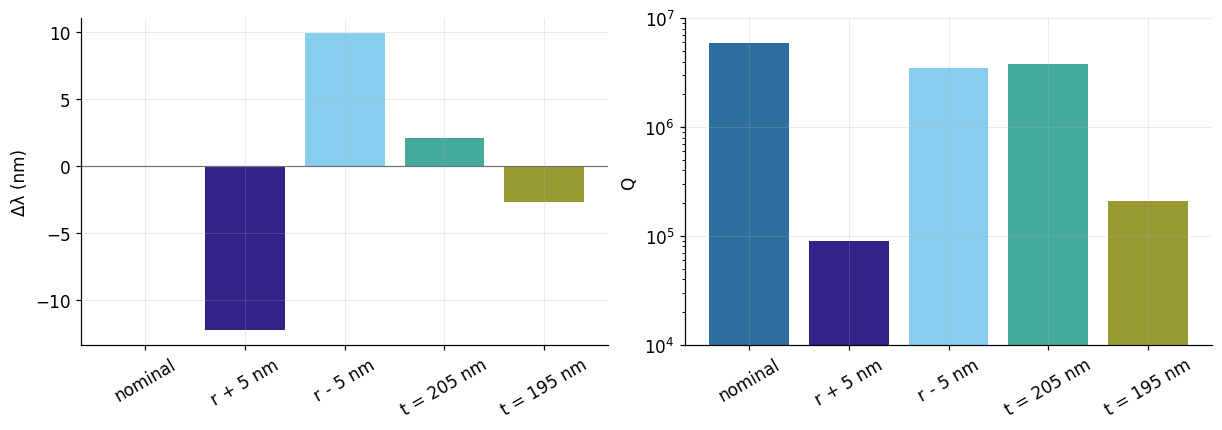

In [6]:
# Wavelength and Q under +-5 nm hole radius and thickness (own N = 15, 64 px/um).
runs = {"nominal": "own_N15", "r + 5 nm": "own_N15_dr+5", "r - 5 nm": "own_N15_dr-5",
        "t = 205 nm": "own_N15_t205", "t = 195 nm": "own_N15_t195"}
tol = {k: load(v) for k, v in runs.items()}
lam0 = 1e3 / tol["nominal"]["f"]
for k, o in tol.items():
    print(f"{k:>11}: {summary(o)}   d lambda {1e3 / o['f'] - lam0:+5.1f} nm")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
names = list(tol)
cols = [style.COLOR_STEEL] + [style.COLOR_CYCLE[i] for i in (0, 1, 2, 4)]
ax0.bar(names, [1e3 / tol[k]["f"] - lam0 for k in names], color=cols)
ax0.axhline(0, color=style.COLOR_REFERENCE, lw=0.8)
ax0.set_ylabel("Δλ (nm)")
ax1.bar(names, [tol[k]["Q"] for k in names], color=cols)
ax1.set_yscale("log"); ax1.set_ylabel("Q"); ax1.set_ylim(1e4, 1e7)
for ax in (ax0, ax1):
    ax.tick_params(axis="x", rotation=30)
fig.savefig(DATA / "fig_nanobeam_tolerance.png", dpi=150, bbox_inches="tight")
plt.show()

The resonance moves by −12 / +10 nm for ±5 nm hole radius and by about ±2–3 nm for ±5 nm
thickness, similar to the L3. Q is much more sensitive: larger holes drop it by almost two orders of magnitude to
9×10⁴, a thinner membrane by more than one order to 2×10⁵, while smaller holes and a thicker membrane leave
it above 10⁶. Larger holes and a thinner membrane both move the band structure up in
frequency, so the mirror's band gap shifts away from the resonance near the taper's centre
and the carefully graded mirror strength is lost. Even the worst case keeps Q ≈ 10⁵, more
than 30× the L3, and close to what fabrication disorder allows in practice.

## 4. L3 vs nanobeam

All values from this series (3D FDTD, 200 nm SiN membrane, n = 2.0) next to the literature.

                              design  lambda        Q     V        F  pattern (um)   Q under +-5 nm
                      L3, final (02)   641.8    3e+03  1.13    2e+02  7.5 × 4.6      1.8e3–4.6e3
   nanobeam, McCutcheon (s = 105 nm)   653.0  2.2e+05  0.61  2.7e+04  10.2 × 0.3     –
                   nanobeam, own N15   642.9  5.9e+06  1.01  4.5e+05  12.9 × 0.3     9e4–4e6
         nanobeam, own N15s (637 nm)   636.6  1.4e+06  1.65  6.4e+04  12.7 × 0.3     –


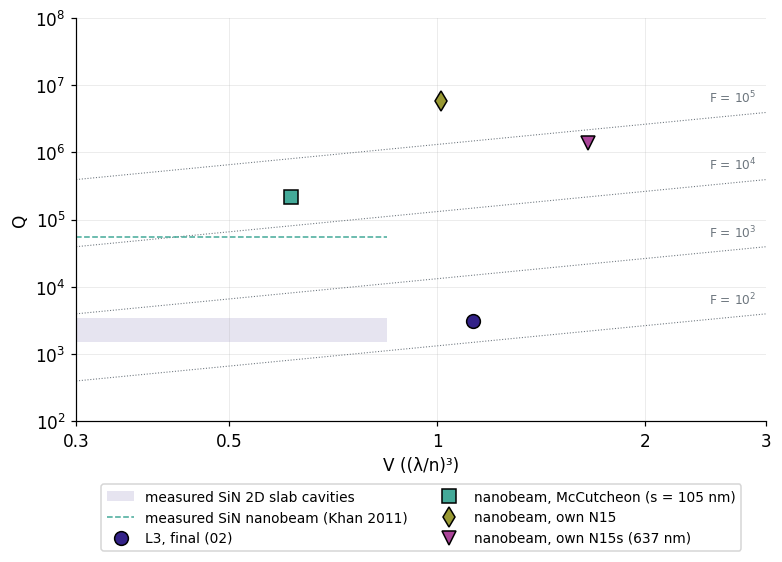

In [7]:
# Comparison table and Q-V map with lines of constant Purcell factor.
l3 = load("l3_final_nb", DATA / "l3")
cases = {
    "L3, final (02)": (l3, "7.5 × 4.6", "1.8e3–4.6e3"),
    "nanobeam, McCutcheon (s = 105 nm)": (own["McCutcheon & Lončar (s = 105 nm)"], "10.2 × 0.3", "–"),
    "nanobeam, own N15": (own["own N = 15"], "12.9 × 0.3", "9e4–4e6"),
    "nanobeam, own N15s (637 nm)": (own["own N = 15, retuned (N15s)"], "12.7 × 0.3", "–"),
}
print(f"{'design':>36} {'lambda':>7} {'Q':>8} {'V':>5} {'F':>8}  pattern (um)   Q under +-5 nm")
for name, (o, size, qtol) in cases.items():
    print(f"{name:>36} {1e3 / o['f']:7.1f} {o['Q']:8.2g} {o['V']:5.2f} {o['purcell']:8.2g}  {size:<13}  {qtol}")

fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
V = np.logspace(np.log10(0.3), np.log10(3), 50)
for e in (2, 3, 4, 5):
    ax.loglog(V, 10 ** e * 4 * np.pi ** 2 / 3 * V, color=style.COLOR_REFERENCE, lw=0.7, ls=":")
    ax.text(2.9, 10 ** e * 4 * np.pi ** 2 / 3 * 2.9 * 1.3, f"F = 10$^{e}$", fontsize=8,
            color=style.COLOR_REFERENCE, ha="right", va="bottom")
ax.axhspan(1.5e3, 3.4e3, xmax=0.45, color=style.COLOR_CYCLE[0], alpha=0.12, lw=0,
           label="measured SiN 2D slab cavities")
ax.axhline(5.5e4, xmax=0.45, color=style.COLOR_CYCLE[2], lw=1, ls="--", label="measured SiN nanobeam (Khan 2011)")
for (name, (o, _, _)), c, m in zip(cases.items(), style.COLOR_CYCLE[::2] + [style.COLOR_PURPLE], "osdv"):
    ax.loglog(o["V"], o["Q"], m, ms=9, color=c, mec="k", ls="none", label=name)
ax.set_xlim(0.3, 3); ax.set_ylim(1e2, 1e8)
ax.set_xticks([0.3, 0.5, 1, 2, 3], ["0.3", "0.5", "1", "2", "3"]); ax.minorticks_off()
ax.set_xlabel("V ((λ/n)³)"); ax.set_ylabel("Q")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)
fig.savefig(DATA / "fig_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

Shaded band: measured SiN 2D slab cavities (Q 1.5–3.4×10³, Barth et al. 2007/2008 and others);
dashed line: best measured SiN nanobeam in the visible (Q 5.5×10⁴, Khan et al. 2011). The
measured cavities have no V on this axis; the marks only show their Q.

| | L3 (2D slab) | nanobeam |
|---|---|---|
| Q (simulated) | 3.0×10³ | 2.2×10⁵ (McCutcheon) – ~10⁶–10⁷ (own taper) |
| V ((λ/n)³) | 1.1 | 0.6 (McCutcheon) – ≈ 1 (own) |
| Purcell F (simulated) | ≈ 200 | ≈ 3×10⁴ (McCutcheon) – ~10⁵–10⁶ (own) |
| Q with ±5 nm radius / thickness | 1.8–4.6×10³ | 9×10⁴ – >10⁶ |
| Δλ with ±5 nm radius | ±9 nm | −12 / +10 nm |
| patterned area | 7.5 × 4.6 µm | 10–13 µm × 0.3 µm beam |
| measured in SiN (literature) | 1.5–3.4×10³ | 5.5×10⁴ |

- In a 200 nm SiN membrane the **nanobeam wins by two to three orders of magnitude in Q and
  Purcell factor**. The L3 is limited to Q ≈ 3×10³ by the light cone, whatever the end-hole
  shifts; the nanobeam's graded mirror keeps its mode out of the light cone and reaches
  Q ≈ 2×10⁵ with McCutcheon's 4-hole taper and above 10⁶ with a 15-hole Quan–Lončar taper.
- The mode volumes are similar (0.6–1.1 (λ/n)³), so Q decides the Purcell factor.
- The L3's Q is robust to ±5 nm errors; the nanobeam's is not (almost two orders of magnitude lower for +5 nm holes), but
  its worst case still exceeds the L3 by 30× and sits near the measured SiN nanobeam record.
  Both cavities shift by ≈ 10 nm per 5 nm of hole radius, so either needs post-fabrication
  tuning (or a sweep of fabricated sizes) to hit 637 nm.
- These results confirm the hypotheses of `literature.md`: the L3 lands in the measured
  1.5–3.4×10³ range, and the nanobeam's Purcell factor exceeds the L3's by more than 100×.
  For SiN emitter coupling in the visible, the nanobeam is the cavity of choice; the L3
  remains useful where a 2D platform, a larger area or a robust Q matters more than a high one.
- **F is an upper bound for a real emitter.** F = 3/(4π²) Q/V assumes an emitter narrower than
  the cavity line (λ/Q ≈ 0.6 pm, ≈ 0.5 GHz at Q = 10⁶), placed at the field maximum and aligned
  with it. The NV zero-phonon line is far broader at room temperature, and an emitter on the
  surface (e.g. a nanodiamond) sees less than the maximum field inside the SiN, so the realized
  enhancement of the high-Q designs is much smaller than these values.

## 5. Summary

- The 3D model reproduces the McCutcheon–Lončar SiN nanobeam: peak Q 2.2×10⁵ (paper 2.3×10⁵),
  V 0.45–0.65 (λ/n)³ over the s scan (paper 0.46–0.64), with the Q peak 10 nm larger in s and
  the wavelength 1.9–2.5 % longer.
- An own Quan–Lončar taper (constant period, 15-hole quadratic taper) raises Q to
  ≈ 6×10⁶ at 643 nm and ≈ 1.4×10⁶ when retuned to 637 nm (order-of-magnitude values; V ≈ 1.0
  (λ/n)³, uncertain by a few tens of percent).
- ±5 nm in hole radius moves the resonance by ≈ 10 nm and drops Q to 9×10⁴ at worst.
- Compared with the L3 of notebook 02 (Q 3.0×10³, V 1.1, F ≈ 200), the nanobeam's Purcell
  factor is two to three orders of magnitude larger.